# Lab Assignment 9 – Cognitive AI
## Model 1: Medicine Bottle Label Reading Assistant

**Objective:** Build a cognitive assistant that reads a medicine-label image, extracts the printed text using Optical Character Recognition (OCR), and attempts to organize useful fields such as medicine name, strength, dosage, expiry date, and manufacturer.

**How it works:** Image upload → image preprocessing → OCR → text extraction → structured summary.

> **Important:** This is an educational prototype. OCR and automatic field extraction can make mistakes. Never use its output to decide a dose, take medicine, or replace advice from a pharmacist/doctor. Always verify the original packaging and prescription.

### Import libraries

In [2]:
!pip -q install easyocr opencv-python-headless pillow matplotlib pandas

In [3]:
import re
import cv2
import easyocr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from IPython.display import display, Markdown

reader = easyocr.Reader(['en'], gpu=False)
print("OCR model loaded successfully.")

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteOCR model loaded successfully.


/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(


### Upload a medicine bottle/label image

Use a clear, well-lit image. Keep the label straight and make sure the text is readable.

Saving istockphoto-2237180725-612x612.jpg to istockphoto-2237180725-612x612.jpg


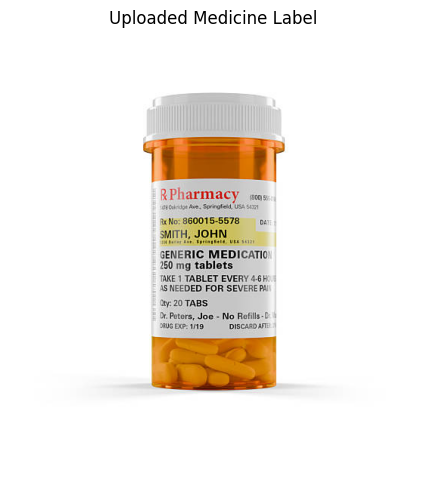

In [4]:
uploaded = files.upload()
image_path = next(iter(uploaded.keys()))

image = cv2.imread(image_path)
if image is None:
    raise ValueError("Could not read the uploaded image. Please upload JPG or PNG.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(10, 6))
plt.imshow(image_rgb)
plt.axis("off")
plt.title("Uploaded Medicine Label")
plt.show()

### Preprocess the image

Convert the image to grayscale and improve contrast. The original image is retained for comparison.

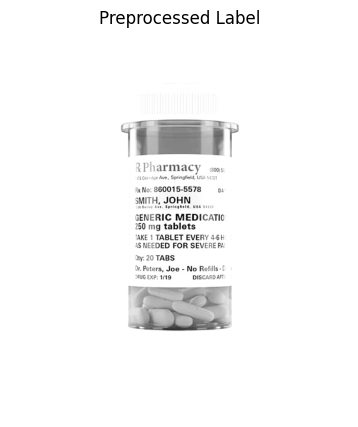

In [5]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
gray = cv2.resize(gray, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_CUBIC)
processed = cv2.convertScaleAbs(gray, alpha=1.3, beta=10)

plt.figure(figsize=(10, 5))
plt.imshow(processed, cmap="gray")
plt.axis("off")
plt.title("Preprocessed Label")
plt.show()

### Read text using OCR

EasyOCR returns detected text and a confidence score for each detected line.

In [6]:
ocr_results = reader.readtext(processed)

if not ocr_results:
    print("No readable text was detected. Try a clearer or closer image.")
else:
    for box, text, confidence in ocr_results:
        print(f"{text}  | confidence: {confidence:.2f}")

full_text = "\\n".join([item[1] for item in ocr_results])
print("\\nCOMPLETE EXTRACTED TEXT:\\n")
print(full_text)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


K  | confidence: 0.62
Pharmacy  | confidence: 1.00
(800  $  | confidence: 0.20
Gcrut  | confidence: 0.02
Springli4 U*571  | confidence: 0.10
@x No: 860015-5578  | confidence: 0.38
Smith; JOHN  | confidence: 0.36
Le  | confidence: 0.01
Viaj  | confidence: 0.02
GENERIC MEDICATIO  | confidence: 0.78
250 mg tablets  | confidence: 0.83
TAKE  | confidence: 0.96
TABLET EVERY 4 6h,  | confidence: 0.37
4S NEEDED FOR SEVERE PAl  | confidence: 0.36
Oty: 20 TABS  | confidence: 0.79
Dr. Poters, Joe  | confidence: 0.70
No Refills - [  | confidence: 0.49
JUG EXP: 1/19  | confidence: 0.49
DISCAADAF  | confidence: 0.66
4c  | confidence: 0.01
\nCOMPLETE EXTRACTED TEXT:\n
K\nPharmacy\n(800  $\nGcrut\nSpringli4 U*571\n@x No: 860015-5578\nSmith; JOHN\nLe\nViaj\nGENERIC MEDICATIO\n250 mg tablets\nTAKE\nTABLET EVERY 4 6h,\n4S NEEDED FOR SEVERE PAl\nOty: 20 TABS\nDr. Poters, Joe\nNo Refills - [\nJUG EXP: 1/19\nDISCAADAF\n4c


 Extract likely medicine information

The following rules look for common label patterns. They are deliberately labelled as *possible* matches because packaging layouts and wording differ.

In [7]:
def find_first(patterns, text, flags=re.IGNORECASE):
    for pattern in patterns:
        match = re.search(pattern, text, flags)
        if match:
            return match.group(1).strip(" :-")
    return "Not detected"

medicine_name = "Not confidently identified"
lines = [line.strip() for line in full_text.splitlines() if line.strip()]

# A possible name is selected from the first short line that is not just a date or instruction.
for line in lines:
    if (len(line) >= 3 and len(line) <= 45
        and not re.search(r'\\b(exp|expiry|mfg|manufactured|batch|lot|mrp|dose|tablet|capsule)\\b', line, re.I)
        and not re.fullmatch(r'[\\d\\W]+', line)):
        medicine_name = line
        break

strength = find_first([
    r'([0-9]+\\s?(?:mg|mcg|g|ml|iu)\\b)',
    r'([0-9]+\\s?%\\b)'
], full_text)

expiry_date = find_first([
    r'(?:exp(?:iry)?\\.?\\s*(?:date)?\\s*[:.-]?\\s*)([0-9]{1,2}[/-][0-9]{2,4}|[0-9]{4}[/-][0-9]{1,2}|[A-Za-z]{3,9}\\s*[0-9]{2,4})',
    r'(?:use before\\s*)([A-Za-z]{3,9}\\s*[0-9]{2,4}|[0-9]{1,2}[/-][0-9]{2,4})'
], full_text)

batch_number = find_first([
    r'(?:batch|lot)\\s*(?:no\\.?|number)?\\s*[:.-]?\\s*([A-Z0-9/-]+)'
], full_text)

manufacturer = find_first([
    r'(?:manufactured by|mfg\\.? by|marketed by)\\s*[:.-]?\\s*([^\\n]+)'
], full_text)

dosage_lines = [line for line in lines if re.search(
    r'\\b(take|dosage|dose|once|twice|daily|before food|after food|tablet|capsule)\\b',
    line, re.I
)]

summary = pd.DataFrame({
    "Field": ["Possible medicine name", "Strength", "Expiry date", "Batch/Lot number", "Manufacturer", "Possible dosage/instruction text"],
    "Extracted result": [
        medicine_name, strength, expiry_date, batch_number, manufacturer,
        " | ".join(dosage_lines) if dosage_lines else "Not detected"
    ]
})
display(summary)

,Field,Extracted result
0,Possible medicine name,Not confidently identified
1,Strength,Not detected
2,Expiry date,Not detected
3,Batch/Lot number,Not detected
4,Manufacturer,Not detected
5,Possible dosage/instruction text,Not detected


 Assistant response

The assistant presents the OCR result in a readable format and reminds the user to verify uncertain fields.

In [8]:
print("MEDICINE LABEL READING ASSISTANT")
print("-" * 45)
for _, row in summary.iterrows():
    print(f"{row['Field']}: {row['Extracted result']}")

print("\\nSafety reminder: Please verify every field on the physical medicine package.")
print("Do not use OCR output to calculate or change a medicine dose.")

MEDICINE LABEL READING ASSISTANT
---------------------------------------------
Possible medicine name: Not confidently identified
Strength: Not detected
Expiry date: Not detected
Batch/Lot number: Not detected
Manufacturer: Not detected
Possible dosage/instruction text: Not detected
\nSafety reminder: Please verify every field on the physical medicine package.
Do not use OCR output to calculate or change a medicine dose.


Save the extracted information

This creates a CSV file that can be downloaded from Colab.

In [9]:
summary.to_csv("medicine_label_summary.csv", index=False)
files.download("medicine_label_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Conclusion

The Medicine Bottle Label Reading Assistant uses a pretrained OCR model to read text from a medicine-label image. OpenCV preprocessing improves the image before OCR, and regular expressions organize some common fields into a summary. The system is a prototype: it does not verify medicines, interpret prescriptions, or provide medical advice.